# Head & Neck vs Lung: Data Linkage & Label Building (Toy Example)

**Problem.** Rybrevant sales (DDD / IntegraChain) show *how many units* an account bought, but not *which indication* they were for. Head & Neck and Lung use the same NDC/SKU.

**Goal of this notebook.** Use a small, made-up dataset to show how we:
1. Link **Claims → HCP → Account → Sales** (OPAL is the bridge)
2. Build an **H&N vs Lung label** for every account
3. Use that label to **split sales units** into H&N and Lung

```
CLAIMS (patient × HCP, has ICD-10)
   │  Step 1: ICD-10 → patient label (HN / LUNG / UNKNOWN)
   │  Step 2: roll up to HCP (NPI)
   ▼
HCP (NPI) ──── OPAL (npi → account_id, weight) ────►  ACCOUNT
                                                        │  Step 4: account H&N share (+ capture rate)
LABS (EGFR tests) → extra lung evidence                 │  Step 5: shrink small samples toward a prior
                                                        ▼
                                SALES (account_id, month, units) → Step 6: split units
```

| Join | Key |
|---|---|
| Claims ↔ HCP ↔ Labs ↔ OPAL | `npi` |
| OPAL ↔ Sales | `account_id` |

> Claims never link to sales directly. **OPAL is the only bridge.**

*All data below is invented for illustration.*

In [1]:
import pandas as pd
from IPython.display import display

pd.set_option("display.precision", 2)

---
## 0. Raw data

### 0a. Sales (DDD / IntegraChain): *what we need to split*
Account level, daily/monthly units, **no diagnosis**.

In [2]:
sales = pd.DataFrame({
    "account_id":   ["ACC_A", "ACC_B", "ACC_C", "ACC_D"],
    "account_type": ["Academic", "Community", "Hospital", "Community"],
    "month":        ["2026-07"] * 4,
    "units":        [100, 50, 30, 20],
})
sales

,account_id,account_type,month,units
0,ACC_A,Academic,2026-07,100
1,ACC_B,Community,2026-07,50
2,ACC_C,Hospital,2026-07,30
3,ACC_D,Community,2026-07,20


### 0b. Claims: *where the labels come from*
Medical claims for amivantamab (HCPCS **J9061**). **One row = one administration.** Each row has the patient, the treating HCP (NPI), and ICD-10 diagnosis codes.

Things to notice:
- **P04** has `C13.9` (hypopharynx, H&N) **and** `C78.0` (*secondary* lung metastasis). This patient is **H&N**, not Lung.
- **P10** has only `C80.1` (unspecified cancer), so we can't tell which one.

In [3]:
claims = pd.DataFrame([
    ("P01", "NPI_1", "2026-05-03", "C34.1"),
    ("P01", "NPI_1", "2026-06-01", "C34.1"),
    ("P02", "NPI_1", "2026-05-10", "C34.9"),
    ("P02", "NPI_1", "2026-06-07", "C34.9"),
    ("P03", "NPI_1", "2026-06-15", "C34.1;C78.0"),
    ("P04", "NPI_2", "2026-05-20", "C13.9;C78.0"),   # H&N primary with lung mets
    ("P04", "NPI_2", "2026-06-17", "C13.9;C78.0"),
    ("P05", "NPI_2", "2026-06-02", "C10.9"),
    ("P06", "NPI_3", "2026-05-11", "C34.2"),
    ("P07", "NPI_3", "2026-06-09", "C32.9"),
    ("P08", "NPI_3", "2026-06-23", "C34.1"),
    ("P09", "NPI_4", "2026-05-05", "C01"),
    ("P09", "NPI_4", "2026-06-02", "C01"),
    ("P10", "NPI_4", "2026-06-12", "C80.1"),         # unspecified
], columns=["patient_id", "npi", "service_date", "icd10"])
claims

,patient_id,npi,service_date,icd10
0,P01,NPI_1,2026-05-03,C34.1
1,P01,NPI_1,2026-06-01,C34.1
2,P02,NPI_1,2026-05-10,C34.9
3,P02,NPI_1,2026-06-07,C34.9
4,P03,NPI_1,2026-06-15,C34.1;C78.0
5,P04,NPI_2,2026-05-20,C13.9;C78.0
6,P04,NPI_2,2026-06-17,C13.9;C78.0
7,P05,NPI_2,2026-06-02,C10.9
8,P06,NPI_3,2026-05-11,C34.2
9,P07,NPI_3,2026-06-09,C32.9


### 0c. HCP master: specialty
Not needed for linking. Useful later as a **feature** and for building **priors**.

In [4]:
hcp = pd.DataFrame({
    "npi":       ["NPI_1", "NPI_2", "NPI_3", "NPI_4", "NPI_5"],
    "specialty": ["Thoracic Onc", "H&N Onc", "Medical Onc", "ENT / H&N Surg", "Thoracic Onc"],
})
hcp

,npi,specialty
0,NPI_1,Thoracic Onc
1,NPI_2,H&N Onc
2,NPI_3,Medical Onc
3,NPI_4,ENT / H&N Surg
4,NPI_5,Thoracic Onc


### 0d. OPAL affiliations: *the bridge*
Maps each HCP to the account(s) where they practice. `weight` = the share of that HCP's activity at that account.

- **NPI_2** splits time **60% ACC_A / 40% ACC_C**
- **NPI_5** is at **ACC_D** but has **no Rybrevant claims**

> If real OPAL has no weights, derive them, e.g. from each HCP's claim volume by site/address, or split evenly.

In [5]:
opal = pd.DataFrame({
    "npi":        ["NPI_1", "NPI_2", "NPI_2", "NPI_3", "NPI_4", "NPI_5"],
    "account_id": ["ACC_A", "ACC_A", "ACC_C", "ACC_B", "ACC_C", "ACC_D"],
    "weight":     [1.0,     0.6,     0.4,     1.0,     1.0,     1.0],
})
opal

,npi,account_id,weight
0,NPI_1,ACC_A,1.0
1,NPI_2,ACC_A,0.6
2,NPI_2,ACC_C,0.4
3,NPI_3,ACC_B,1.0
4,NPI_4,ACC_C,1.0
5,NPI_5,ACC_D,1.0


### 0e. Lab data: *extra lung evidence*
EGFR biomarker tests are ordered almost only for lung patients, so they give **negative examples** (not H&N) and a **lung-leaning prior** for HCPs/accounts with no claims.

In [6]:
labs = pd.DataFrame({
    "patient_id": ["P02", "P11", "P12"],
    "npi":        ["NPI_1", "NPI_5", "NPI_5"],
    "test":       ["EGFR exon20", "EGFR L858R", "EGFR ex19del"],
})
labs

,patient_id,npi,test
0,P02,NPI_1,EGFR exon20
1,P11,NPI_5,EGFR L858R
2,P12,NPI_5,EGFR ex19del


---
## Step 1: Label each patient from ICD-10

| ICD-10 | Meaning | Label |
|---|---|---|
| C00–C14, C30–C32, C76.0 | Head & neck primary sites | **HN** |
| C34 | Lung primary | **LUNG** |
| C77–C79 (e.g. C78.0) | *Secondary* / metastatic | **ignored**: tells us about spread, not the primary |
| anything else | | **UNKNOWN** |

Rules:
1. Label each **claim** from its codes (both HN and LUNG present → `AMBIGUOUS`).
2. Give each **patient** one label: the most frequent known label across their claims.
3. If a patient is still UNKNOWN but has an **EGFR lab test**, label them LUNG.

In [7]:
HN_PREFIXES   = tuple([f"C{i:02d}" for i in range(0, 15)] + ["C30", "C31", "C32", "C76.0"])
LUNG_PREFIXES = ("C34",)

def label_codes(codes: str) -> str:
    codes = codes.split(";")
    hn   = any(c.startswith(HN_PREFIXES)   for c in codes)
    lung = any(c.startswith(LUNG_PREFIXES) for c in codes)
    if hn and lung: return "AMBIGUOUS"
    if hn:          return "HN"
    if lung:        return "LUNG"
    return "UNKNOWN"

claims["claim_label"] = claims["icd10"].apply(label_codes)

def patient_label(s):
    known = s[s.isin(["HN", "LUNG"])]
    return known.mode().iloc[0] if len(known) else "UNKNOWN"

pt = claims.groupby("patient_id")["claim_label"].apply(patient_label).rename("patient_label")
claims = claims.join(pt, on="patient_id")

# Lab evidence upgrades UNKNOWN -> LUNG
lab_lung = set(labs["patient_id"])
claims.loc[claims["patient_id"].isin(lab_lung) & (claims["patient_label"] == "UNKNOWN"), "patient_label"] = "LUNG"

claims[["patient_id", "npi", "icd10", "claim_label", "patient_label"]]

,patient_id,npi,icd10,claim_label,patient_label
0,P01,NPI_1,C34.1,LUNG,LUNG
1,P01,NPI_1,C34.1,LUNG,LUNG
2,P02,NPI_1,C34.9,LUNG,LUNG
3,P02,NPI_1,C34.9,LUNG,LUNG
4,P03,NPI_1,C34.1;C78.0,LUNG,LUNG
5,P04,NPI_2,C13.9;C78.0,HN,HN
6,P04,NPI_2,C13.9;C78.0,HN,HN
7,P05,NPI_2,C10.9,HN,HN
8,P06,NPI_3,C34.2,LUNG,LUNG
9,P07,NPI_3,C32.9,HN,HN


✅ **P04** (`C13.9;C78.0`) is correctly **HN**, so the lung-mets code didn't fool us.
✅ **P10** stays **UNKNOWN** and will be left out of the share calculation.

---
## Step 2: Roll up to the HCP (NPI)

Count **administrations** (claim rows) per HCP per label within a **look-back window**.

- **Why administrations, not patients?** Sales are in *units*. A patient on therapy for 6 months uses far more units than a patient with 1 dose, and administrations follow that.
- **Why a window/lag?** Claims arrive late and are incomplete. Here we use **May–Jun claims to label July sales**. On real data, test rolling windows of 3–6 months.

In [8]:
window = claims[(claims["service_date"] >= "2026-05-01") & (claims["service_date"] <= "2026-06-30")]

hcp_counts = (window.pivot_table(index="npi", columns="patient_label", values="patient_id",
                                 aggfunc="count", fill_value=0)
              .reindex(columns=["HN", "LUNG", "UNKNOWN"], fill_value=0)
              .reset_index())
hcp_counts = hcp.merge(hcp_counts, on="npi", how="left").fillna(0)
hcp_counts

,npi,specialty,HN,LUNG,UNKNOWN
0,NPI_1,Thoracic Onc,0.0,5.0,0.0
1,NPI_2,H&N Onc,3.0,0.0,0.0
2,NPI_3,Medical Onc,1.0,2.0,0.0
3,NPI_4,ENT / H&N Surg,2.0,0.0,1.0
4,NPI_5,Thoracic Onc,0.0,0.0,0.0


Notice **NPI_5** has zeros everywhere: no claims captured. We'll come back to that.

---
## Step 3: Link HCP → Account through OPAL

Join the HCP counts to OPAL on `npi`, then **multiply the counts by the affiliation weight**.

So NPI_2's 3 H&N administrations become **1.8 at ACC_A** and **1.2 at ACC_C**. An HCP who works at several accounts is never double-counted.

In [9]:
linked = opal.merge(hcp_counts, on="npi", how="left")
for c in ["HN", "LUNG", "UNKNOWN"]:
    linked[c] = linked[c] * linked["weight"]
linked

,npi,account_id,weight,specialty,HN,LUNG,UNKNOWN
0,NPI_1,ACC_A,1.0,Thoracic Onc,0.0,5.0,0.0
1,NPI_2,ACC_A,0.6,H&N Onc,1.8,0.0,0.0
2,NPI_2,ACC_C,0.4,H&N Onc,1.2,0.0,0.0
3,NPI_3,ACC_B,1.0,Medical Onc,1.0,2.0,0.0
4,NPI_4,ACC_C,1.0,ENT / H&N Surg,2.0,0.0,1.0
5,NPI_5,ACC_D,1.0,Thoracic Onc,0.0,0.0,0.0


In [10]:
acct = linked.groupby("account_id")[["HN", "LUNG", "UNKNOWN"]].sum().reset_index()
acct

,account_id,HN,LUNG,UNKNOWN
0,ACC_A,1.8,5.0,0.0
1,ACC_B,1.0,2.0,0.0
2,ACC_C,3.2,0.0,1.0
3,ACC_D,0.0,0.0,0.0


---
## Step 4: Account-level label: raw H&N share + capture rate

- **Raw H&N share** = HN / (HN + LUNG)
- **Capture rate** = administrations seen in claims ÷ administrations implied by sales. It tells us **how much to trust** the label.

`UNITS_PER_ADMIN = 4` is a **toy assumption**. Replace it with the real Rybrevant dosing (vials per infusion).

In [11]:
UNITS_PER_ADMIN = 4      # toy assumption
WINDOW_MONTHS   = 2      # May-Jun

acct = sales.merge(acct, on="account_id", how="left").fillna({"HN": 0, "LUNG": 0, "UNKNOWN": 0})
acct["labeled_n"]    = acct["HN"] + acct["LUNG"]
acct["raw_hn_share"] = (acct["HN"] / acct["labeled_n"]).where(acct["labeled_n"] > 0)
acct["expected_admins_per_month"] = acct["units"] / UNITS_PER_ADMIN
acct["capture_rate"] = (acct["labeled_n"] / WINDOW_MONTHS) / acct["expected_admins_per_month"]

acct[["account_id", "units", "HN", "LUNG", "labeled_n", "raw_hn_share", "capture_rate"]]

,account_id,units,HN,LUNG,labeled_n,raw_hn_share,capture_rate
0,ACC_A,100,1.8,5.0,6.8,0.26,0.14
1,ACC_B,50,1.0,2.0,3.0,0.33,0.12
2,ACC_C,30,3.2,0.0,3.2,1.00,0.21
3,ACC_D,20,0.0,0.0,0.0,NaN,0.00


⚠️ Two problems with the raw label:
- **ACC_C = 100% H&N**, but that's based on only ~3 administrations. Is it really zero lung?
- **ACC_D = NaN**: no claims at all, so there's no label.

That's why we need Step 5.

---
## Step 5: Shrink small samples toward a prior (beta-binomial)

$$\text{estimated H\&N share} = \frac{HN + \alpha}{HN + LUNG + \alpha + \beta}$$

- The prior acts like **K "pseudo-administrations"** at the prior share: $\alpha = \text{prior} \times K$, $\beta = (1-\text{prior}) \times K$
- **Lots of data** → the account's own share wins. **Little data** → it gets pulled toward the prior.
- **No data** → the prior *is* the estimate.

**ACC_D:** no claims, but its HCP orders EGFR tests (lab data), so we give it a **lung-leaning prior** (5% H&N) instead of the national average.

> In real data: use **peer-group priors** (account type × specialty mix) instead of one national number, and tune **K** with a masking test (see the end of the notebook).

In [12]:
prior_mean = acct["HN"].sum() / acct["labeled_n"].sum()
K = 4
alpha, beta = prior_mean * K, (1 - prior_mean) * K
print(f"prior H&N share = {prior_mean:.2f}   K = {K}   alpha = {alpha:.2f}   beta = {beta:.2f}")

acct["alpha"], acct["beta"] = alpha, beta

# Lab signal -> lung-leaning prior for accounts with no claims
lab_accts = opal[opal["npi"].isin(labs["npi"])]["account_id"].unique()
no_claims = acct["account_id"].isin(lab_accts) & (acct["labeled_n"] == 0)
acct.loc[no_claims, ["alpha", "beta"]] = [0.2, 3.8]

acct["hn_share_est"] = (acct["HN"] + acct["alpha"]) / (acct["labeled_n"] + acct["alpha"] + acct["beta"])
acct["confidence"]   = pd.cut(acct["labeled_n"], [-1, 0, 3, 1e9], labels=["prior only", "low", "ok"])

acct[["account_id", "HN", "LUNG", "labeled_n", "raw_hn_share", "hn_share_est", "confidence"]]

prior H&N share = 0.46   K = 4   alpha = 1.85   beta = 2.15


,account_id,HN,LUNG,labeled_n,raw_hn_share,hn_share_est,confidence
0,ACC_A,1.8,5.0,6.8,0.26,0.34,ok
1,ACC_B,1.0,2.0,3.0,0.33,0.41,low
2,ACC_C,3.2,0.0,3.2,1.00,0.70,ok
3,ACC_D,0.0,0.0,0.0,NaN,0.05,prior only


| Account | Raw → Shrunk | Why |
|---|---|---|
| ACC_A | 0.26 → 0.34 | Most data, so it moves a little |
| ACC_C | **1.00 → 0.70** | Few observations, so it's pulled back from an extreme |
| ACC_D | NaN → **0.05** | No claims, so it falls back on the lab-informed prior |

*(The 46% prior is only because the toy is small. Early in launch the real H&N share will likely be in single digits.)*

---
## Step 6: Apply the label to sales

In [13]:
acct["hn_units"]   = acct["units"] * acct["hn_share_est"]
acct["lung_units"] = acct["units"] - acct["hn_units"]

final = acct[["account_id", "account_type", "units", "hn_share_est", "confidence", "hn_units", "lung_units"]]
display(final)
print(f"TOTAL {acct['units'].sum()} units  ->  H&N {acct['hn_units'].sum():.1f}   Lung {acct['lung_units'].sum():.1f}")

,account_id,account_type,units,hn_share_est,confidence,hn_units,lung_units
0,ACC_A,Academic,100,0.34,ok,33.76,66.24
1,ACC_B,Community,50,0.41,low,20.33,29.67
2,ACC_C,Hospital,30,0.70,ok,21.03,8.97
3,ACC_D,Community,20,0.05,prior only,1.00,19.00


TOTAL 200 units  ->  H&N 76.1   Lung 123.9


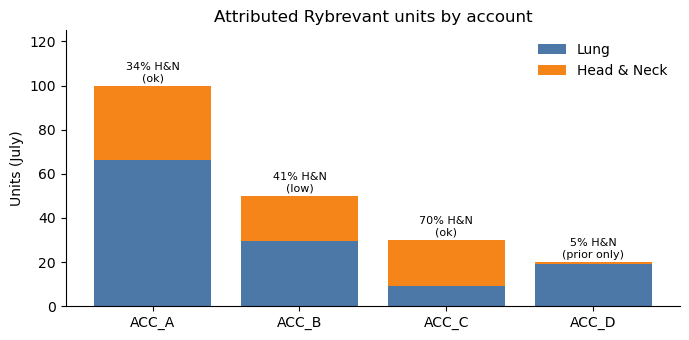

In [14]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(final["account_id"], final["lung_units"], label="Lung", color="#4C78A8")
ax.bar(final["account_id"], final["hn_units"], bottom=final["lung_units"], label="Head & Neck", color="#F58518")
for i, r in final.reset_index(drop=True).iterrows():
    ax.text(i, r["units"] + 2, f"{r['hn_share_est']:.0%} H&N\n({r['confidence']})", ha="center", fontsize=8)
ax.set_ylabel("Units (July)"); ax.set_ylim(0, 125)
ax.set_title("Attributed Rybrevant units by account")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
plt.tight_layout(); plt.show()

---
## What comes next

### The label becomes a training set (method C: ML model)
The account-month table from Steps 4–5 is a **supervised training set**:

| Column | Role |
|---|---|
| `hn_share_est` (or raw share) | **target** |
| `labeled_n` | **sample weight** (trust high-capture rows more) |
| specialty mix, EGFR lab volume, Lazcluze co-sales, order size/cadence, account type | **features** |

The model then predicts the share for accounts like ACC_D (poor claims capture) using a smarter prior than a flat average.

In [15]:
# Sketch of the training table (features would come from HCP master, labs, Lazcluze sales, order patterns)
spec_mix = (opal.merge(hcp, on="npi")
                .assign(is_hn_spec=lambda d: d["specialty"].str.contains("H&N|ENT").astype(float) * d["weight"],
                        is_thoracic=lambda d: d["specialty"].str.contains("Thoracic").astype(float) * d["weight"])
                .groupby("account_id")[["is_hn_spec", "is_thoracic"]].sum())
egfr_tests = (labs.merge(opal, on="npi").groupby("account_id").size().rename("egfr_tests"))

train = (acct.set_index("account_id")[["account_type", "units", "labeled_n", "hn_share_est"]]
             .join(spec_mix).join(egfr_tests).fillna({"egfr_tests": 0})
             .rename(columns={"labeled_n": "sample_weight", "hn_share_est": "target_hn_share"}))
train

,account_type,units,sample_weight,target_hn_share,is_hn_spec,is_thoracic,egfr_tests
account_id,,,,,,,
ACC_A,Academic,100,6.8,0.34,0.6,1.0,1.0
ACC_B,Community,50,3.0,0.41,0.0,0.0,0.0
ACC_C,Hospital,30,3.2,0.70,1.4,0.0,0.0
ACC_D,Community,20,0.0,0.05,0.0,1.0,2.0


### Validating on real data
Ground truth is scarce, so check the approach several ways:
1. **Pre-launch backtest:** before the H&N launch, every account should come out at **≈0% H&N**.
2. **Masking test:** take accounts with high capture, hide most of their claims, and check whether the method recovers the true share. Use this to tune **K** and the window length.
3. **Field-confirmed accounts:** known H&N-only or lung-only sites.
4. **National reconciliation:** the sum of H&N units should match projected claims or patient-services totals.

### Pitfalls the real pipeline must handle
- **Mets codes** (C77–C79) must not decide the indication (see P04).
- **Claims capture differs by payer and channel** (Medicare vs commercial, 340B). Check whether capture differs between H&N and lung patients.
- **HCPs at several accounts**: always allocate by weight, never count in full at each account.
- **Claims latency**: lag the window.
- **Off-label and clinical-trial use** appears in sales with no matching claims.